# Model 2 results: how human emissions raise CO2 in the air

**Question:** each year, how much does atmospheric CO2 rise (ppm), and how much of that is explained by human emissions and El Niño?

**Where this fits in the project chain:** people and income → emissions (Model 1) → **CO2 in the air (Model 2)** → India's climate (Model 3).

**Data:** `data/model_ready/m2_co2_growth.csv`, one row per year, 1960–2024 (65 rows). Built by the DVC stage `features_m2`.

**How models were judged:** three walk-forward exams. Each model trains only on earlier years and predicts years it has never seen:

| Exam | Trained on | Tested on |
|---|---|---|
| 1 | up to 1990 | 1991–2002 |
| 2 | up to 2000 | 2001–2012 |
| 3 (final holdout) | up to 2009 | 2010–2024 |

**Main score, skill:** how much smaller a model's typical error is than the simple guess "this year's rise = last year's rise". 0% means no better, negative means worse.

**Champion rule, fixed before training:** the reference is the emissions-only model. A challenger needs average skill more than 5 points higher AND must beat the reference in at least 2 of 3 exams. Models that use volcano years can't be champion, because eruptions can't be known in advance.

This notebook only reads the saved results and refits small linear models for the graphs. Run it from the repo root or from `notebooks/`, after `python src/models/train_m2_co2.py`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data/model_ready/m2_co2_growth.csv"
REP = ROOT / "reports/models/m2"
GTC_PER_PPM = 2.124          # GtC per 1 ppm of CO2 (from memory in the handoff)
FEATS = ["total_emissions", "nino34", "nino34_lag1"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

df = pd.read_csv(DATA).sort_values("year").reset_index(drop=True)
long = pd.read_csv(REP / "comparison_long.csv")
summary = json.loads((REP / "summary.json").read_text())
train09 = df[df.year <= 2009]
volcano_years = df.loc[df.volcano_flag == 1, "year"].tolist()

print(f"{len(df)} rows, {df.year.min()}-{df.year.max()}")
print("Volcano years flagged (from memory, verify):", volcano_years)
print("Champion:", summary["champion"], "|", summary["reason"])
df.head()

65 rows, 1960-2024
Volcano years flagged (from memory, verify): [1963, 1964, 1982, 1983, 1991, 1992]
Champion: linear_nino | average skill 33.4% vs reference 25.4% (needs > +5 points) and wins 3 of 3 exams


,year,growth_ppm,total_emissions,fossil_emissions,land_use_emissions,nino34,nino34_lag1,volcano_flag,split_time
0,1960,0.71,4.639061,2.561941,2.077120,0.068333,0.146667,0,train
1,1961,0.78,4.652060,2.569593,2.082467,-0.013333,0.068333,0,train
2,1962,0.56,4.608526,2.660273,1.948253,-0.217500,-0.013333,0,train
3,1963,0.57,4.699811,2.802068,1.897743,0.667500,-0.217500,1,train
4,1964,0.49,4.771940,2.954277,1.817663,-0.362500,0.667500,1,train


## 1. The raw story: emissions, CO2 rise and El Niño over time

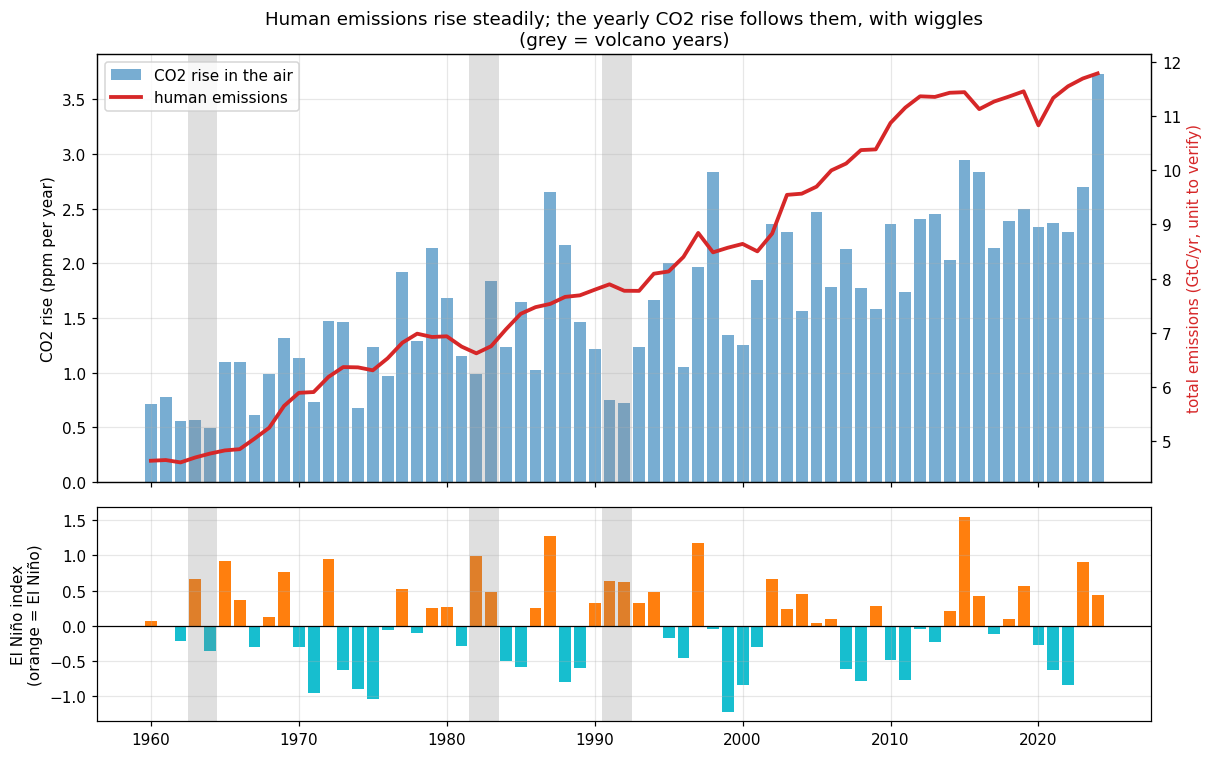

In [2]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1]})
a1.bar(df.year, df.growth_ppm, color="tab:blue", alpha=0.6, label="CO2 rise in the air")
a1.set_ylabel("CO2 rise (ppm per year)")
b = a1.twinx()
b.plot(df.year, df.total_emissions, color="tab:red", lw=2.5, label="human emissions")
b.set_ylabel("total emissions (GtC/yr, unit to verify)", color="tab:red")
b.grid(False)
a2.bar(df.year, df.nino34, color=np.where(df.nino34 > 0, "tab:orange", "tab:cyan"))
a2.axhline(0, color="k", lw=0.8)
a2.set_ylabel("El Niño index\n(orange = El Niño)")
for y in volcano_years:
    for ax in (a1, a2):
        ax.axvspan(y - 0.5, y + 0.5, color="grey", alpha=0.25, lw=0)
h1, l1 = a1.get_legend_handles_labels(); h2, l2 = b.get_legend_handles_labels()
a1.legend(h1 + h2, l1 + l2, loc="upper left")
a1.set_title("Human emissions rise steadily; the yearly CO2 rise follows them, with wiggles\n"
             "(grey = volcano years)")
plt.tight_layout(); plt.show()

**How to read this graph:** the blue bars show how much CO2 the air gained each year. The red line shows how much CO2 humans emitted. The bottom panel shows El Niño: orange bars are warm El Niño years, blue are cool La Niña years. Grey bands mark volcano years.

**What to notice:** the bars grow as the red line grows, which is the long-term link. The bars also jump up and down from year to year, and the jumps tend to come after orange bars, which is the El Niño effect. Bars dip in the grey bands.

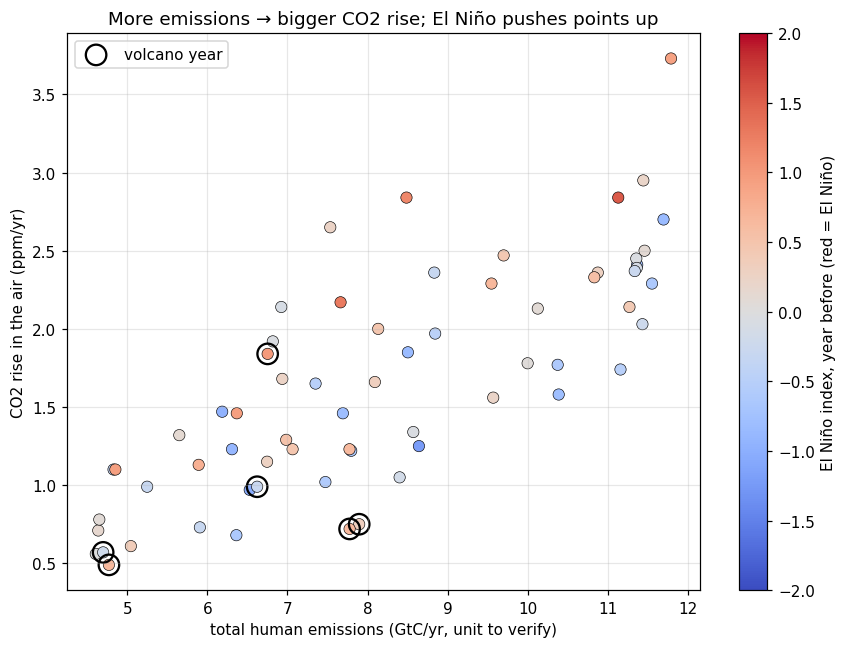

Correlation emissions vs CO2 rise: 0.78


In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(df.total_emissions, df.growth_ppm, c=df.nino34_lag1, cmap="coolwarm",
                s=55, edgecolor="k", lw=0.4, vmin=-2, vmax=2)
v = df[df.volcano_flag == 1]
ax.scatter(v.total_emissions, v.growth_ppm, facecolor="none", edgecolor="k", s=180, lw=1.5,
           label="volcano year")
plt.colorbar(sc, label="El Niño index, year before (red = El Niño)")
ax.set_xlabel("total human emissions (GtC/yr, unit to verify)")
ax.set_ylabel("CO2 rise in the air (ppm/yr)")
ax.set_title("More emissions → bigger CO2 rise; El Niño pushes points up")
ax.legend(); plt.tight_layout(); plt.show()
print("Correlation emissions vs CO2 rise:", round(df.total_emissions.corr(df.growth_ppm), 2))

**How to read this graph:** each dot is one year. Moving right means more emissions, moving up means a bigger CO2 rise. Colour shows El Niño in the year before. Circled dots are volcano years.

**What to notice:** the dots slope upward, so more emissions go with a bigger CO2 rise. At the same emissions, red dots (after El Niño) tend to sit higher and blue dots lower. Circled volcano dots tend to sit lower.

## 2. How every model did in the three exams

In [4]:
order = ["same_as_last_year", "average_growth", "linear_emissions", "share_no_intercept",
         "linear_nino", "ridge_nino", "gbm_nino", "linear_nino_volcano"]
order = [m for m in order if m in set(long.model)]
labels = long.drop_duplicates("exam").set_index("exam")["test_years"]

skill = long.pivot(index="model", columns="exam", values="skill").loc[order] * 100
skill.columns = [f"exam {e} ({labels[e]})" for e in skill.columns]
skill["average"] = skill.mean(axis=1)
mae = long.pivot(index="model", columns="exam", values="mae").loc[order]
mae.columns = [f"MAE exam {e}" for e in mae.columns]

table = skill.round(1).join(mae.round(3))
table.index = [f"{m}  ★ champion" if m == summary["champion"] else m for m in table.index]
table

,exam 1 (1991-2002),exam 2 (2001-2012),exam 3 (2010-2024),average,MAE exam 1,MAE exam 2,MAE exam 3
same_as_last_year,0.0,0.0,0.0,0.0,0.602,0.540,0.423
average_growth,8.9,-35.1,-151.3,-59.2,0.548,0.729,1.064
linear_emissions,6.2,39.7,30.3,25.4,0.564,0.326,0.295
share_no_intercept,17.3,37.6,17.5,24.1,0.497,0.337,0.349
linear_nino ★ champion,6.9,45.2,48.0,33.4,0.560,0.296,0.220
ridge_nino,8.6,43.7,40.6,30.9,0.550,0.304,0.252
gbm_nino,9.4,-10.4,-18.2,-6.4,0.545,0.596,0.500
linear_nino_volcano,15.1,47.9,47.6,36.9,0.511,0.281,0.222


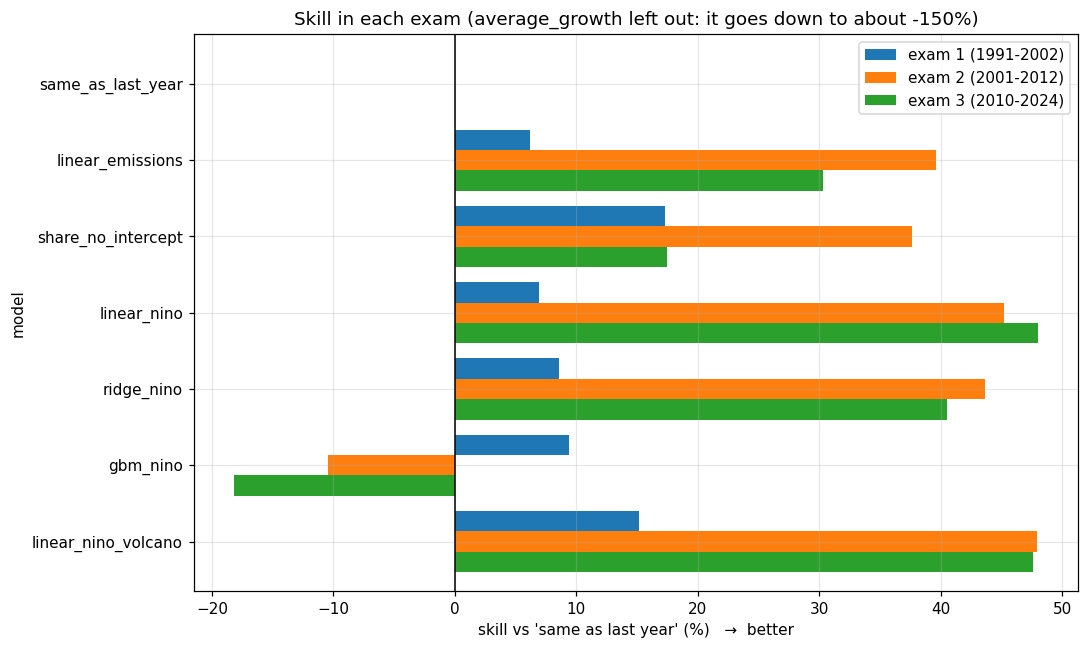

In [5]:
plot = skill.drop(columns="average").drop(index="average_growth", errors="ignore")
ax = plot.plot.barh(figsize=(10, 6), width=0.8)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("skill vs 'same as last year' (%)   →  better")
ax.set_title("Skill in each exam (average_growth left out: it goes down to about -150%)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**How to read this table and graph:** each bar is one model in one exam. Bars to the right of zero beat the "same as last year" guess. MAE is the typical error in ppm per year (smaller is better).

**What to notice:**
- **All linear models beat both baselines in every exam.** Emissions explain the CO2 rise in years the models never saw.
- **Adding El Niño (`linear_nino`) helps in every exam.** It's the champion under the fixed rule.
- **Ridge is slightly worse than plain linear.** With only three inputs there's little overfitting to fix, so shrinking the weights just loses some signal.
- **Gradient boosting (`gbm_nino`) does fine in exam 1, then goes negative in exams 2 and 3.** Section 4 shows why.
- **The volcano model helps mostly in exam 1**, the exam that contains the Pinatubo years.

## 3. Final exam close-up: 2010–2024, trained only up to 2009

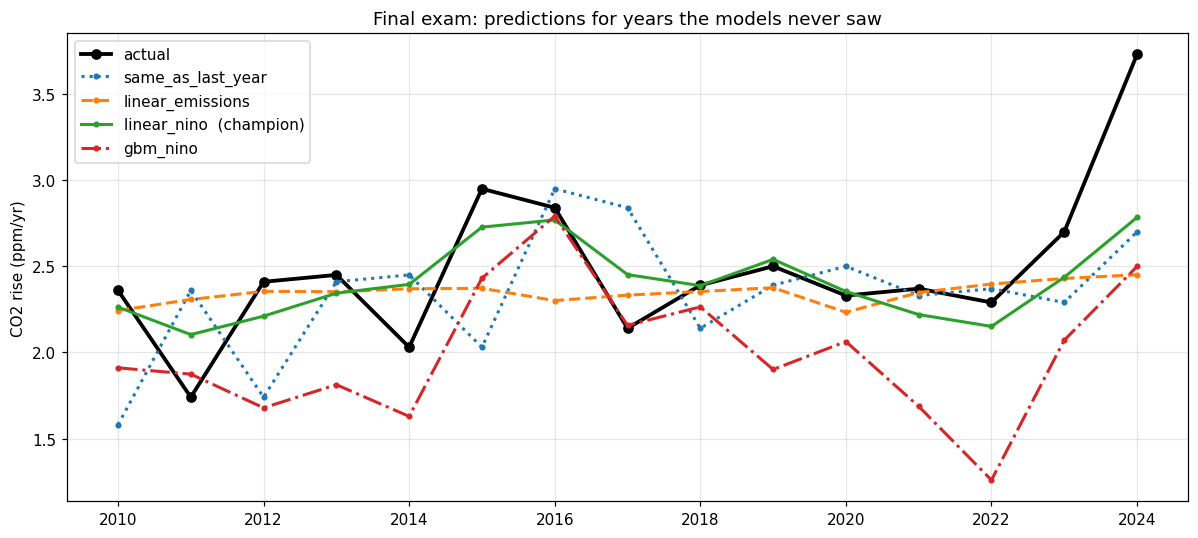

In [6]:
show = ["same_as_last_year", "linear_emissions", summary["champion"], "gbm_nino"]
show = list(dict.fromkeys(m for m in show if (REP / f"pred_{m}.csv").exists()))
style = {"same_as_last_year": ":", "linear_emissions": "--", "gbm_nino": "-."}
fig, ax = plt.subplots(figsize=(11, 5))
first = pd.read_csv(REP / f"pred_{show[0]}.csv")
ax.plot(first.year, first.actual, "k-o", lw=2.5, label="actual")
for m in show:
    p = pd.read_csv(REP / f"pred_{m}.csv")
    ls = "-" if m == summary["champion"] else style.get(m, "--")
    ax.plot(p.year, p.predicted, ls, lw=2, marker=".",
            label=m + ("  (champion)" if m == summary["champion"] else ""))
ax.set_ylabel("CO2 rise (ppm/yr)")
ax.set_title("Final exam: predictions for years the models never saw")
ax.legend(); plt.tight_layout(); plt.show()

**How to read this graph:** the black line is what really happened, and the coloured lines are each model's predictions made with training data up to 2009 only.

**What to notice:** "same as last year" is always one step late. Emissions-only gets the general level but is a smooth line. The champion also follows many of the ups and downs, because it knows the El Niño values. Gradient boosting stays low and flat, because the 2010s had higher emissions than anything it was trained on.

## 4. Why tree models fail here: they cannot go beyond what they have seen

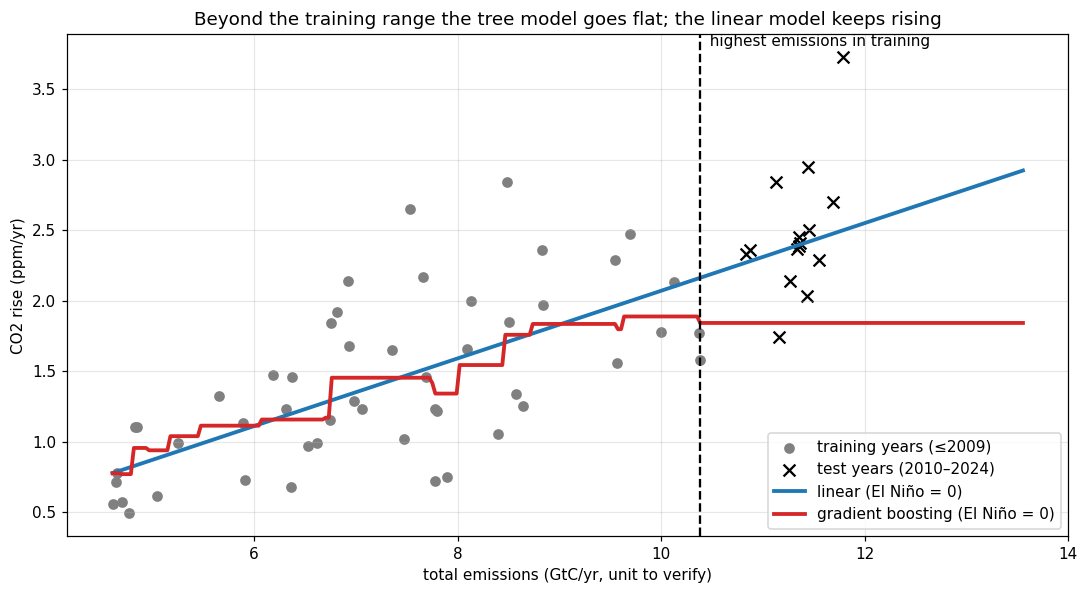

In [7]:
lin = LinearRegression().fit(train09[FEATS], train09.growth_ppm)
gbm = GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                random_state=0).fit(train09[FEATS], train09.growth_ppm)
grid = pd.DataFrame({"total_emissions": np.linspace(df.total_emissions.min(),
                                                    df.total_emissions.max() * 1.15, 300),
                     "nino34": 0.0, "nino34_lag1": 0.0})
test = df[df.year > 2009]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(train09.total_emissions, train09.growth_ppm, color="grey", label="training years (≤2009)")
ax.scatter(test.total_emissions, test.growth_ppm, color="k", marker="x", s=60,
           label="test years (2010–2024)")
ax.plot(grid.total_emissions, lin.predict(grid[FEATS]), "tab:blue", lw=2.5, label="linear (El Niño = 0)")
ax.plot(grid.total_emissions, gbm.predict(grid[FEATS]), "tab:red", lw=2.5, label="gradient boosting (El Niño = 0)")
ax.axvline(train09.total_emissions.max(), color="k", ls="--")
ax.text(train09.total_emissions.max(), ax.get_ylim()[1], "  highest emissions in training",
        va="top")
ax.set_xlabel("total emissions (GtC/yr, unit to verify)"); ax.set_ylabel("CO2 rise (ppm/yr)")
ax.set_title("Beyond the training range the tree model goes flat; the linear model keeps rising")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**How to read this graph:** both models were trained on the grey dots (up to 2009). The lines show what each model predicts for any emissions level, with El Niño set to neutral. The dashed line marks the highest emissions seen in training. The black crosses are the real test years.

**What to notice:** to the right of the dashed line, the red tree line goes flat. A tree can only repeat values it saw in training, so it can't predict a bigger rise for bigger emissions. The blue linear line keeps rising and stays close to the crosses. Emissions keep rising, so this is the main reason Model 2 uses linear models. The same problem would hit Model 3, because future CO2 is also beyond the training range.

## 5. How much of our emissions stays in the air?

All values below assume total_emissions is in GtC/yr (verify in features_m2_co2.py)
Bookkeeping 1960-2024: emitted 533 GtC, air gained 230 GtC -> 43% stayed in the air
Years where the air gained more than humans emitted: 0
Yearly share range: 20% (1992) to 75% (1987)
No-intercept model (train <=2009): share = 42%
With-intercept model (train <=2009): slope share = 48%, intercept = -0.23 ppm/yr


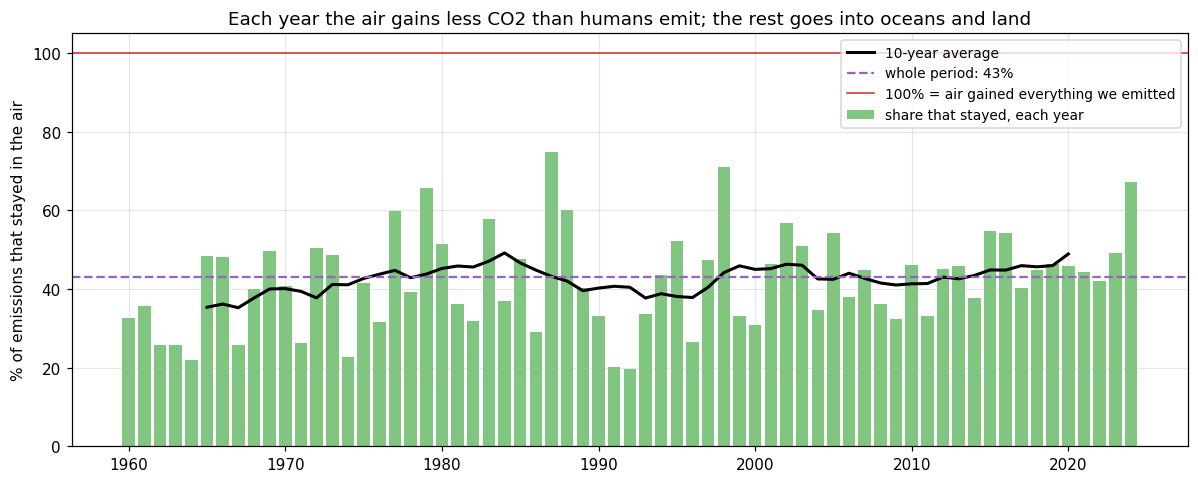

In [8]:
gained_gtc = df.growth_ppm * GTC_PER_PPM
yearly_share = gained_gtc / df.total_emissions
whole_period = gained_gtc.sum() / df.total_emissions.sum()
no_int = LinearRegression(fit_intercept=False).fit(train09[["total_emissions"]], train09.growth_ppm)
with_int = LinearRegression().fit(train09[["total_emissions"]], train09.growth_ppm)

print("All values below assume total_emissions is in GtC/yr (verify in features_m2_co2.py)")
print(f"Bookkeeping {df.year.min()}-{df.year.max()}: emitted {df.total_emissions.sum():.0f} GtC, "
      f"air gained {gained_gtc.sum():.0f} GtC -> {whole_period:.0%} stayed in the air")
print(f"Years where the air gained more than humans emitted: {(yearly_share > 1).sum()}")
print(f"Yearly share range: {yearly_share.min():.0%} ({df.year[yearly_share.idxmin()]}) "
      f"to {yearly_share.max():.0%} ({df.year[yearly_share.idxmax()]})")
print(f"No-intercept model (train <=2009): share = {no_int.coef_[0] * GTC_PER_PPM:.0%}")
print(f"With-intercept model (train <=2009): slope share = {with_int.coef_[0] * GTC_PER_PPM:.0%}, "
      f"intercept = {with_int.intercept_:.2f} ppm/yr")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(df.year, yearly_share * 100, color="tab:green", alpha=0.6, label="share that stayed, each year")
ax.plot(df.year, yearly_share.rolling(10, center=True).mean() * 100, "k", lw=2,
        label="10-year average")
ax.axhline(whole_period * 100, color="tab:purple", ls="--", label=f"whole period: {whole_period:.0%}")
ax.axhline(100, color="tab:red", lw=1, label="100% = air gained everything we emitted")
ax.set_ylabel("% of emissions that stayed in the air")
ax.set_title("Each year the air gains less CO2 than humans emit; the rest goes into oceans and land")
ax.legend(loc="upper right", fontsize=9); plt.tight_layout(); plt.show()

**How to read this graph:** each bar shows what percentage of that year's human emissions ended up in the air. The rest was absorbed by oceans and plants. The red line at 100% would mean the air gained everything humans emitted.

**What to notice:**
- If every bar stays below 100%, the air never gained more CO2 than humans emitted. Human emissions alone are therefore enough to explain the whole rise, with no need for a natural source. This is the **human-cause evidence** from our own data.
- The share jumps around a lot from year to year (El Niño and volcanoes), but its long-term average is fairly steady.
- The **no-intercept model's share** is the clean model estimate. Compare it with the Global Carbon Budget's published value before quoting it in the report.

## 6. What El Niño adds, and what volcanoes add

Champion-style model (train <=2009) weights:
  total_emissions  +0.240
  nino34           +0.171
  nino34_lag1      +0.231
Correlation of leftover (after emissions) with El Niño same year: 0.32, year before: 0.38


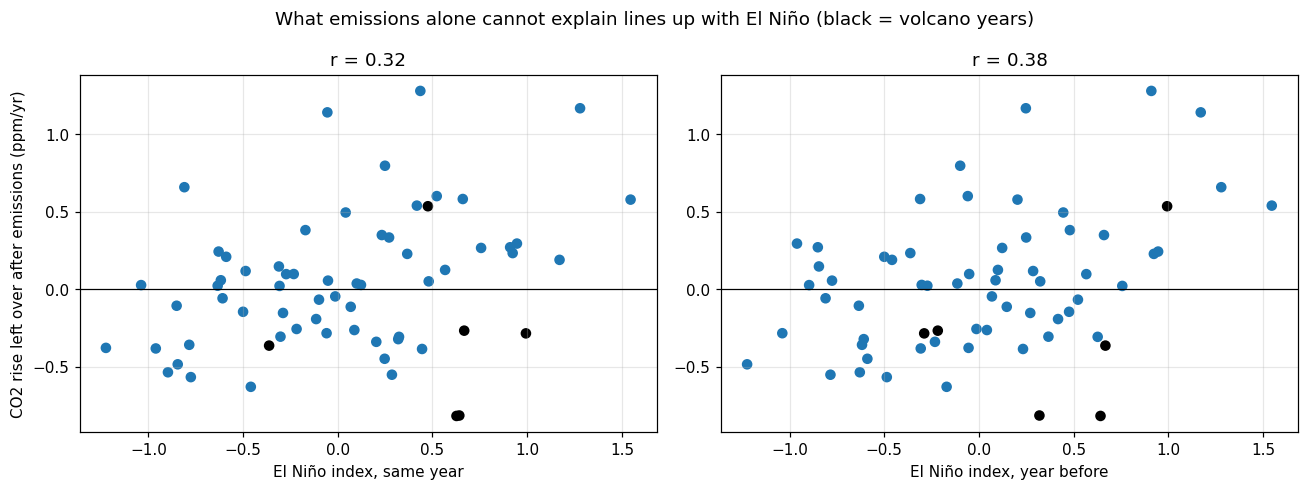

In [9]:
resid = df.growth_ppm - with_int.predict(df[["total_emissions"]])
nino_model = LinearRegression().fit(train09[FEATS], train09.growth_ppm)
print("Champion-style model (train <=2009) weights:")
for f, c in zip(FEATS, nino_model.coef_):
    print(f"  {f:16s} {c:+.3f}")
print(f"Correlation of leftover (after emissions) with El Niño same year: {resid.corr(df.nino34):.2f}, "
      f"year before: {resid.corr(df.nino34_lag1):.2f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, name in ((a1, "nino34", "same year"), (a2, "nino34_lag1", "year before")):
    ax.scatter(df[col], resid, c=np.where(df.volcano_flag == 1, "k", "tab:blue"), s=35)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(f"El Niño index, {name}")
    ax.set_title(f"r = {resid.corr(df[col]):.2f}")
a1.set_ylabel("CO2 rise left over after emissions (ppm/yr)")
fig.suptitle("What emissions alone cannot explain lines up with El Niño (black = volcano years)")
plt.tight_layout(); plt.show()

**How to read this graph:** we first predict each year's CO2 rise from emissions alone. The leftover (actual minus predicted) is what emissions can't explain. Each dot plots that leftover against El Niño. Black dots are volcano years.

**What to notice:** an upward slope means El Niño years leave extra CO2 in the air. In hot, dry El Niño years, tropical forests and soils absorb less CO2 (a known mechanism, not something our model proves). Black volcano dots tend to sit below zero: after big eruptions, the air gained less CO2 than emissions suggest.

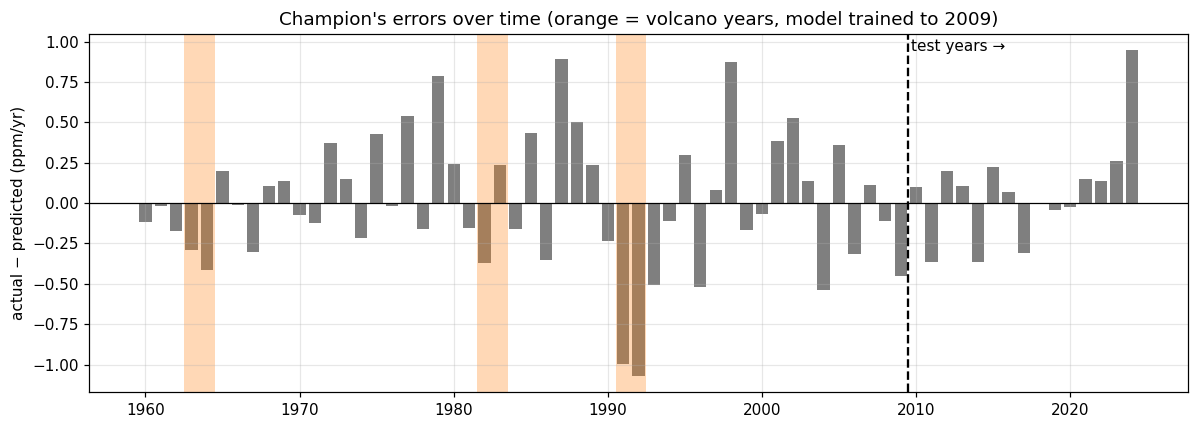

In [10]:
pred_all = nino_model.predict(df[FEATS])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(df.year, df.growth_ppm - pred_all, color="tab:gray")
for y in volcano_years:
    ax.axvspan(y - 0.5, y + 0.5, color="tab:orange", alpha=0.3, lw=0)
ax.axvline(2009.5, color="k", ls="--"); ax.text(2009.7, ax.get_ylim()[1] * 0.9, "test years →")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("actual − predicted (ppm/yr)")
ax.set_title("Champion's errors over time (orange = volcano years, model trained to 2009)")
plt.tight_layout(); plt.show()

**How to read this graph:** bars above zero mean the air gained more CO2 than the champion predicted, bars below mean less. Orange bands are volcano years, and years right of the dashed line were never seen in training.

**What to notice:** the biggest misses below zero sit in or right after the orange bands. That's what the volcano flag fixes, and why it mostly helps exam 1. Test-year errors look about the same size as training-year errors, so the model didn't simply memorise the training years.

## 7. Conclusions for the report

1. **Human emissions explain the yearly rise of CO2 in the air.** A one-input linear model beat "same as last year" in all three exams (skill 6%, 40%, 30%) on years it never saw. A fixed average rise failed badly (down to −151%), because the yearly rise keeps growing with emissions.
2. **Our own data shows the rise is human-caused** (section 5). If the air gained less than humans emitted in every year, human emissions are enough to explain the whole increase. Oceans and land absorb the rest.
3. **El Niño explains much of the year-to-year wobble.** Adding it raised average skill from 25% to 33% and won all 3 exams, so `linear_nino` is the champion under the rule fixed in advance. In 2010–2024, R² went from 0.02 to 0.49.
4. **Volcanoes matter, but only around eruptions.** The volcano flag raised exam 1 skill from 7% to 15% (Pinatubo period) and added little elsewhere. It explains the past but can't forecast. The volcano years still need verifying.
5. **Simpler is better here.** Ridge was slightly worse (31% vs 33%). Gradient boosting failed (−6% average) because trees can't predict beyond the highest emissions seen in training (section 4). Linear models are the right choice when the future lies outside the training range, and the same applies to Model 3.
6. **The share of emissions that stays in the air** is estimated in section 5. Quote it only after checking the emissions unit and comparing it with the Global Carbon Budget figure.

## 8. Honest limits

- Only 65 yearly rows, and each exam tests 12–15 years, so the skill numbers are rough.
- R² is negative for most models in exams 1 and 2. Over a short window, most variation is year-to-year wobble, and R² compares against the test-period average, which no model can know in advance. Skill against a real forecast is the fairer score.
- The model uses the same year's emissions and El Niño, so it explains rather than forecasts. For scenarios, emissions come from a chosen path and El Niño is replayed from history as a range.
- Oceans and land may absorb a smaller share as CO2 keeps rising. A model trained on the past can't see that, so long-range scenarios should be treated as what-ifs.
- This shows a strong, physically sensible link, not a controlled experiment. Not yet verified: emissions unit (GtC/yr), the 2.124 GtC/ppm factor, and the volcano years.